In [50]:
from datasets import load_dataset

# Streams the dataset without a full download
dataset = load_dataset("wikimedia/wikipedia", "20231101.en", split="train", streaming=True)

# Extracts only the first 50 rows
sampled_subset = list(dataset.take(100))

In [51]:
len(sampled_subset)

100

In [44]:
import spacy
nlp = spacy.load("en_core_web_sm")

In [52]:
from tqdm import tqdm
all_lemmas=list()
for article in tqdm(sampled_subset):
    doc = nlp(article.get('text').lower()[:500])
    unique_lemmas = {token.lemma_ for token in doc}
    all_lemmas.extend(unique_lemmas)
all_lemmas_unique = set(all_lemmas)
print(len(all_lemmas_unique))

100%|███████████████████████████████████████| 100/100 [00:00<00:00, 105.43it/s]

2503


In [53]:
with open('lemma_list.txt', 'w') as file:
    for item in all_lemmas_unique:
        file.write(f"{item}\n")

In [47]:
sample_article = list(sampled_subset)[0]
sample_article_text = sample_article.get('text')

In [48]:
doc = nlp(sample_article_text)
for token in doc[:5]:
    print(token.text, token.pos_, token.dep_, token.lemma_)

Anarchism NOUN nsubj anarchism
is AUX ROOT be
a DET det a
political ADJ amod political
philosophy NOUN attr philosophy


In [54]:
with open("Sample_Passages.txt", "r", encoding="utf-8") as file:
    passages = file.read()

print(passages)


Jon was a young shepherd, and he lived with his sheep on the side of a high, rocky mountain. He knew every field and every tree on that mountain, and the dark did not trouble him. But on one long, dark hour, something was different. The moon was full, the snow lay over the field, and the sky was full of stars. The sheep would not rest. They kept close together, and their eyes were wide.
Jon took his lamp and went out. At first he saw no one. Then he heard a sound, long and low, and he knew it was a wolf. A wolf could kill many sheep in one nighttime, and Jon had no help. He held his lamp high and spoke to the animals, and they came to him.
The wolf came closer. Jon could see its eyes in the light of the lamp. He did not move, and he did not call out. He kept the sheep behind him, a single young man with a single lamp, and he held the eyes of the wolf for a long time.
The wolf was also very old. Jon saw this, and he knew. It had come to the mountain to hunt for food, not to fight. He ga

In [55]:
passage_doc = nlp(passages.lower())
all_passage_lemmas_unique = {token.lemma_ for token in passage_doc}
print(len(all_passage_lemmas_unique))

182


In [57]:
with open('passage_lemma_list.txt', 'w') as file:
    for item in all_passage_lemmas_unique:
        file.write(f"{item}\n")

In [63]:
with open("sentences.txt", "r", encoding="utf-8") as file:
    sentences = file.read().splitlines()

In [67]:
passage_sentences=[sent.text for sent in passage_doc.sents]

In [68]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/distiluse-base-multilingual-cased-v1")

sentence_embeddings = model.encode(sentences)
passage_embeddings = model.encode(passage_sentences)

similarities = model.similarity(sentence_embeddings, passage_embeddings)
print(similarities.shape)

Loading weights: 100%|█████████████████████| 100/100 [00:00<00:00, 7248.56it/s]


torch.Size([99, 65])


In [69]:
print(similarities)

tensor([[ 0.1400, -0.0191,  0.1205,  ...,  0.0179,  0.1896,  0.0765],
        [ 0.0865,  0.0030,  0.0997,  ..., -0.0370,  0.0322,  0.0884],
        [-0.0201, -0.0112,  0.1148,  ..., -0.0564,  0.0936,  0.0854],
        ...,
        [-0.0366, -0.0104, -0.0295,  ...,  0.0756, -0.0202,  0.1043],
        [ 0.0369, -0.0113,  0.1583,  ...,  0.2444,  0.0042,  0.2391],
        [-0.0114, -0.0327, -0.0031,  ...,  0.1646,  0.1917,  0.2849]])


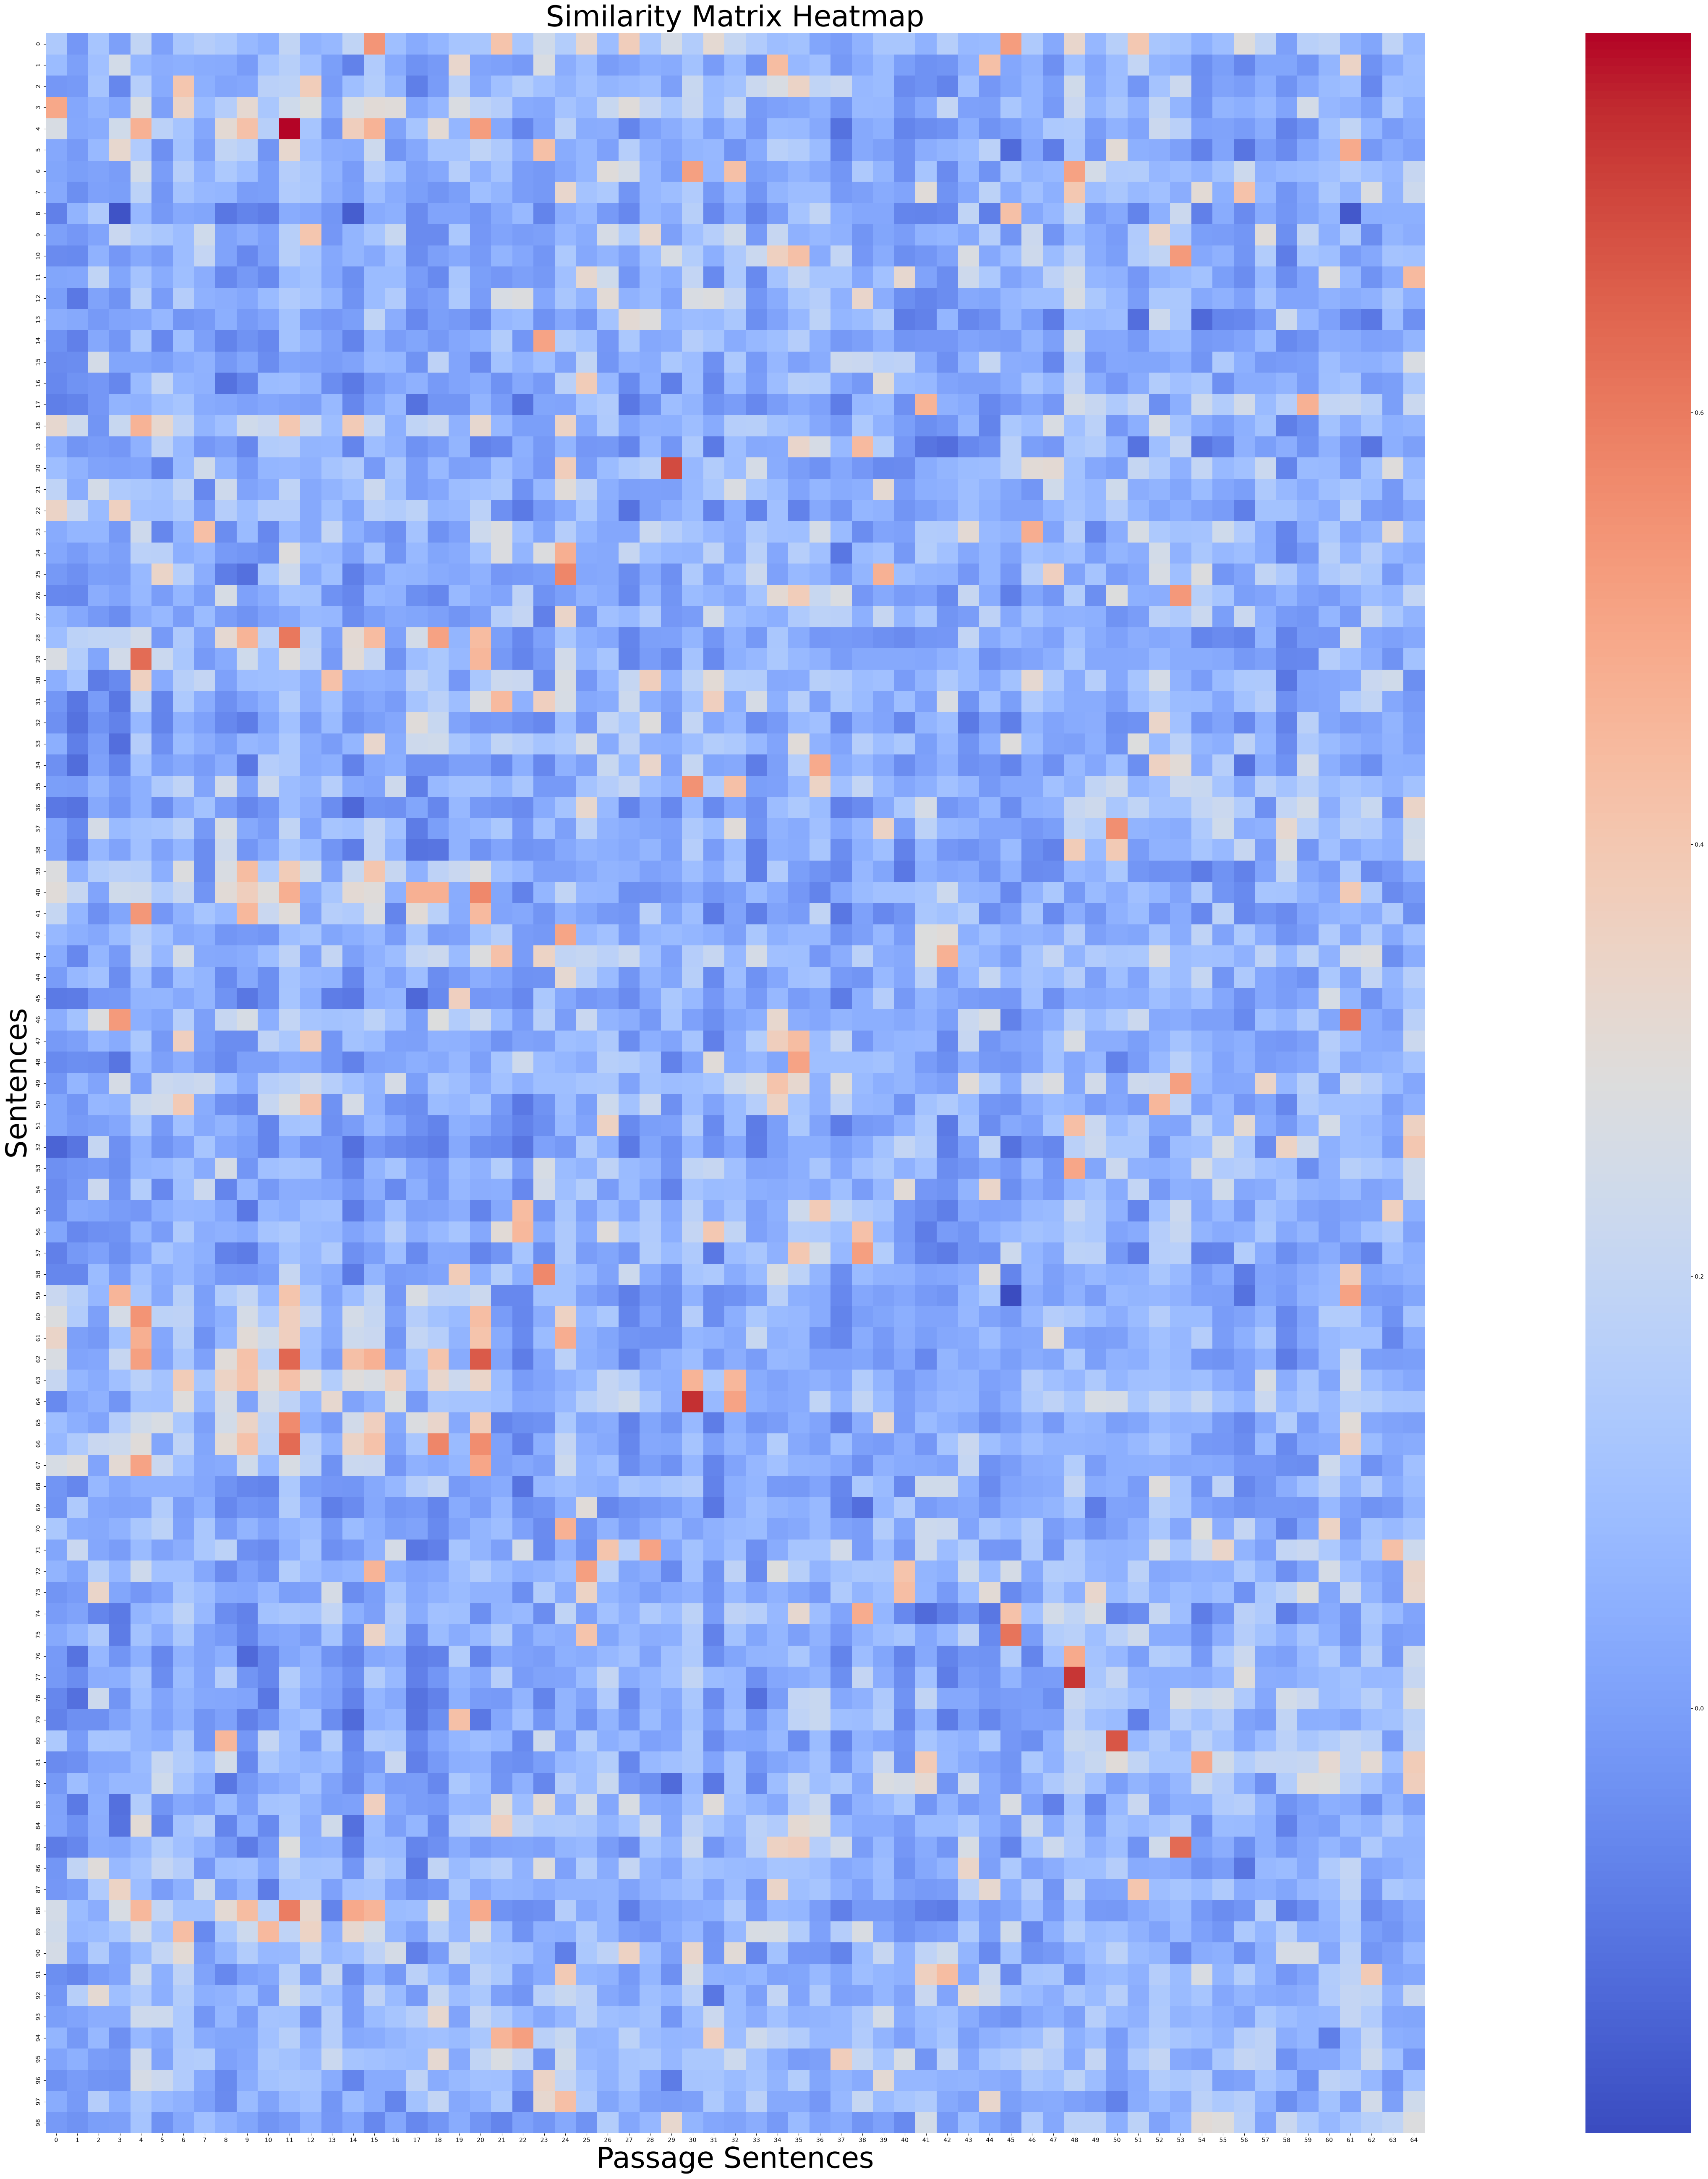

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Plot using Seaborn
plt.figure(figsize=(99, 65))
sns.heatmap(similarities, annot=False, cmap="coolwarm", fmt=".2f", square=True)

plt.title("Similarity Matrix Heatmap", fontsize=50)
plt.xlabel("Passage Sentences", fontsize=50)
plt.ylabel("Sentences", fontsize=50)


plt.show()

In [80]:
print(similarities[20,29])
print(sentences[20])
print(passage_sentences[29])

tensor(0.6905)
Who is that man on the road?
“who is this man?”


In [81]:
print(similarities[77,48])
print(sentences[77])
print(passage_sentences[48])

tensor(0.7257)
The instrument is a saxophone.
in it was a saxophone.


In [82]:
print(similarities[4,11])
print(sentences[4])
print(passage_sentences[11])

tensor(0.7756)
The wolf is near the sheep.
the wolf came closer.


In [83]:
print(similarities[64,30])
print(sentences[64])
print(passage_sentences[30])

tensor(0.7308)
Paul hears the call and comes.
paul called out.


In [84]:
(similarities > .5).sum().item()

47

In [86]:
import torch
torch.nonzero(similarities > .5).tolist()

[[0, 15],
 [0, 45],
 [4, 11],
 [4, 20],
 [6, 30],
 [6, 48],
 [10, 53],
 [14, 23],
 [20, 29],
 [25, 24],
 [26, 53],
 [28, 11],
 [28, 18],
 [29, 4],
 [35, 30],
 [37, 50],
 [40, 20],
 [41, 4],
 [42, 24],
 [46, 3],
 [46, 61],
 [48, 35],
 [49, 53],
 [53, 48],
 [57, 38],
 [58, 23],
 [59, 61],
 [60, 4],
 [62, 4],
 [62, 11],
 [62, 20],
 [64, 30],
 [64, 32],
 [65, 11],
 [66, 11],
 [66, 18],
 [66, 20],
 [67, 4],
 [67, 20],
 [71, 28],
 [72, 25],
 [75, 45],
 [77, 48],
 [80, 50],
 [85, 53],
 [88, 11],
 [94, 22]]